In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

In [2]:
metric_4_path = Path("metric_4_regular_agents.csv")
metric_3_path = Path("metric_3_regular_agents.csv")

result = Path("results/py/cv.png")
result.parent.mkdir(parents=True, exist_ok=True)

metric_4 = pd.read_csv(metric_4_path)
metric_3 = pd.read_csv(metric_3_path)

cols_4 = ['tot_cflights', 'tot_bflights', 'ctotal_pax', 'btotal_pax']
names_4 = ['Зарег. рейсов', 'Посажено рейсов', 'Зарег. пассажиров', 'Посажено пассажиров']
cols_3 = ['avg_break']
names_3 = ['Ср. длина перерыва']

In [3]:
def cv(df, columns, names):
    means = df[columns].mean()
    stds = df[columns].std(ddof=1)
    cvs = (stds / means) * 100
    
    report = pd.DataFrame({
        'Критерий': names,
        'Ср. арифм.': means,
        'Отклонение': stds,
        'Коэффициент вариации (%)': cvs
    })
    print(report.to_string(index=False))
    return report

In [4]:
flights_paxs = cv(metric_4, cols_4, names_4)
breaks = cv(metric_3, cols_3, names_3)

           Критерий  Ср. арифм.  Отклонение  Коэффициент вариации (%)
      Зарег. рейсов   58.785714    4.995052                  8.497052
    Посажено рейсов   27.071429    3.173551                 11.722881
  Зарег. пассажиров 3434.071429  360.639062                 10.501793
Посажено пассажиров 3344.214286  538.909323                 16.114677
          Критерий  Ср. арифм.  Отклонение  Коэффициент вариации (%)
Ср. длина перерыва   92.571429     8.59977                  9.289875


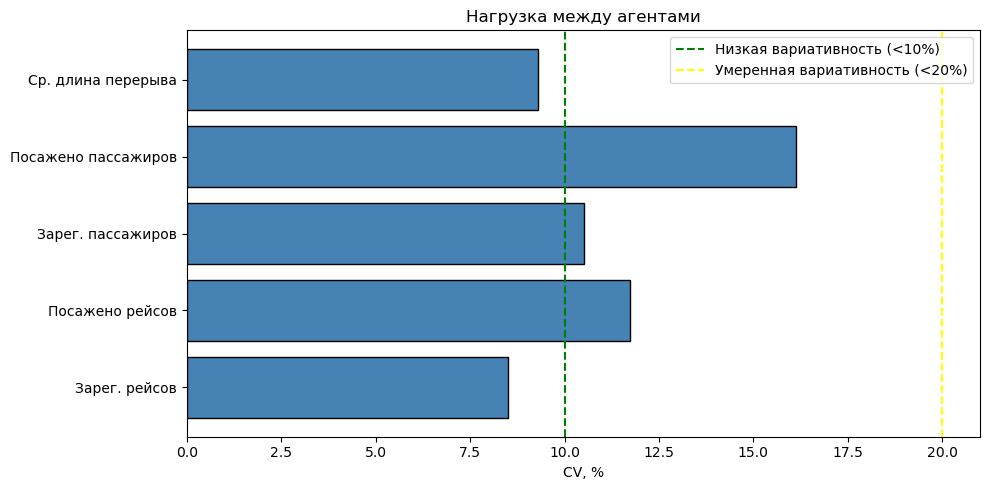

In [5]:
metrics = pd.concat([flights_paxs, breaks], ignore_index=True)
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(metrics["Критерий"], metrics["Коэффициент вариации (%)"], color="steelblue", edgecolor="black")
ax.axvline(10, color="green", linestyle="--", label="Низкая вариативность (<10%)")
ax.axvline(20, color="yellow", linestyle="--", label="Умеренная вариативность (<20%)")
ax.set_xlabel("CV, %")
ax.set_title("Нагрузка между агентами")
ax.legend()
plt.tight_layout()


plt.savefig(result, bbox_inches='tight', dpi=300)
plt.show()